# 12. Core Implementation

In [1]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
text = ["I love this movie!", "Terrible plot."]

tokens = tokenizer(
    text,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

print(f"Các keys trả về từ tokenizer: {tokens.keys()}")
print(f"Input IDs:\n{tokens['input_ids']}")
print(f"Attention Mask:\n{tokens['attention_mask']}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Các keys trả về từ tokenizer: KeysView({'input_ids': tensor([[ 101, 1045, 2293, 2023, 3185,  999,  102],
        [ 101, 6659, 5436, 1012,  102,    0,    0]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0]])})
Input IDs:
tensor([[ 101, 1045, 2293, 2023, 3185,  999,  102],
        [ 101, 6659, 5436, 1012,  102,    0,    0]])
Attention Mask:
tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0]])


# 13. Core Implementation — Classification Head

In [2]:
import torch
import torch.nn as nn
from transformers import BertModel

class BertSentimentClassifier(nn.Module):
    def __init__(self, pretrained_model_name='bert-base-uncased', num_classes=2):
        super().__init__()
        self.bert = BertModel.from_pretrained(pretrained_model_name)

        self.classifier_head = nn.Sequential(
            nn.Dropout(0.1),
            nn.Linear(768, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        last_hidden_state = outputs.last_hidden_state
        cls_representation = last_hidden_state[:, 0, :]

        logits = self.classifier_head(cls_representation)
        return logits

model = BertSentimentClassifier()
model.eval()
with torch.no_grad():
    logits = model(tokens['input_ids'], tokens['attention_mask'])
    probs = torch.softmax(logits, dim=1)
    predictions = torch.argmax(probs, dim=1)

print(f"Xác suất dự đoán (Softmax): \n{probs}")
print(f"Nhãn dự đoán (Predictions): {predictions}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Xác suất dự đoán (Softmax): 
tensor([[0.4404, 0.5596],
        [0.5071, 0.4929]])
Nhãn dự đoán (Predictions): tensor([1, 0])


# 14. Experiment 1 — Pretrained vs From Scratch

In [5]:
import torch
import torch.nn as nn
import time
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import BertTokenizer, BertModel, BertConfig
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 30000
seq_len = 64
batch_size = 64
epochs = 5
learning_rate = 2e-5

(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(num_words=vocab_size)
X_train_pad = pad_sequences(X_train_full[:2000], maxlen=seq_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_full[:500], maxlen=seq_len, padding='post', truncating='post')

def create_loader(X, y):
    masks = (X != 0).astype(int)
    X_t = torch.tensor(X, dtype=torch.long)
    masks_t = torch.tensor(masks, dtype=torch.long)
    y_t = torch.tensor(y[:len(X)], dtype=torch.float32).unsqueeze(1)
    return DataLoader(TensorDataset(X_t, masks_t, y_t), batch_size=batch_size, shuffle=True)

train_loader = create_loader(X_train_pad, y_train_full)
test_loader = create_loader(X_test_pad, y_test_full)

class TransformerFromScratch(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 128)
        self.pos_encoder = nn.Parameter(torch.zeros(1, seq_len, 128))
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=2, dim_feedforward=512, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.fc = nn.Linear(128, 1)

    def forward(self, input_ids, attention_mask):
        x = self.embedding(input_ids) + self.pos_encoder
        pad_mask = (attention_mask == 0)
        x = self.encoder(x, src_key_padding_mask=pad_mask)
        cls_out = x[:, 0, :]
        return self.fc(cls_out)

class PretrainedTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = BertModel.from_pretrained('prajjwal1/bert-tiny')
        self.fc = nn.Linear(128, 1)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_out = outputs.last_hidden_state[:, 0, :]
        return self.fc(cls_out)

def train_and_eval(model, name):
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    criterion = nn.BCEWithLogitsLoss()
    total_params = sum(p.numel() for p in model.parameters())

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for inputs, masks, labels in train_loader:
            inputs, masks, labels = inputs.to(device), masks.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs, masks)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    t_time = time.time() - start_time

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, masks, labels in test_loader:
            inputs, masks = inputs.to(device), masks.to(device)
            logits = model(inputs, masks)
            preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_params, t_time, acc, f1

print("\nĐang train Transformer From Scratch...")
res_scratch = train_and_eval(TransformerFromScratch(), "From Scratch")

print("Đang train Pretrained Transformer (BERT-tiny)...")
res_pretrained = train_and_eval(PretrainedTransformer(), "Pretrained")

print("\n" + "="*80)
print(f"{'Model':<30} | {'Accuracy':<10} | {'F1':<10} | {'Time (s)':<10} | {'# Parameters'}")
print("-" * 80)
print(f"{'Transformer from scratch':<30} | {res_scratch[2]:<10.4f} | {res_scratch[3]:<10.4f} | {res_scratch[1]:<10.2f} | {res_scratch[0]:,}")
print(f"{'Pretrained Transformer':<30} | {res_pretrained[2]:<10.4f} | {res_pretrained[3]:<10.4f} | {res_pretrained[1]:<10.2f} | {res_pretrained[0]:,}")


Đang train Transformer From Scratch...
Đang train Pretrained Transformer (BERT-tiny)...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Model                          | Accuracy   | F1         | Time (s)   | # Parameters
--------------------------------------------------------------------------------
Transformer from scratch       | 0.4980     | 0.6480     | 80.73      | 4,244,865
Pretrained Transformer         | 0.5320     | 0.5301     | 66.83      | 4,386,049


1. Representation (Biểu diễn ngôn ngữ) khác nhau như thế nào?

- Transformer from scratch: Biểu diễn ngôn ngữ tại epoch đầu tiên hoàn toàn là những vector rác (do khởi tạo ngẫu nhiên). Mô hình phải tự mò mẫm định nghĩa lại khái niệm ngữ pháp, từ loại, và phân loại cảm xúc từ con số không. Kết quả là nó học được một tập hợp representation rất nông, bị bó hẹp và overfit chặt chẽ vào văn phong cụ thể của tập IMDb.

- Pretrained Transformer: Bắt đầu với một bộ não đã được nhồi nhét ngữ cảnh sâu sắc từ hàng chục GB văn bản. Các vector biểu diễn của nó có khả năng phân biệt rạch ròi ngữ nghĩa phức tạp, hiểu được phủ định, từ đồng nghĩa và cấu trúc câu đa dạng ngay cả trước khi nhìn thấy nhãn cảm xúc của bài toán.

2. Training data cần thiết khác nhau như thế nào?

- Transformer from scratch: Cực kỳ khát dữ liệu. Để các trọng số Attention thoát khỏi trạng thái nhiễu ngẫu nhiên và hội tụ, nó cần một kho dữ liệu khổng lồ với hàng chục ngàn mẫu nhãn. Nếu data quá nhỏ, loss có thể giảm nhưng nó không hề hiểu ngôn ngữ mà chỉ học vẹt, dẫn đến Accuracy trên tập Test rất tệ.

- Pretrained Transformer: Rất tiết kiệm dữ liệu. Vì chỉ cần thực hiện Fine-tuning, mô hình pretrained có thể cho ra Accuracy và F1 vượt trội chỉ với vài trăm đến vài ngàn mẫu dữ liệu.

3. Chi phí tính toán khác nhau như thế nào?

- Chi phí Pretraining: Việc sinh ra một pretrained model tốn hàng ngàn giờ chạy trên hàng chục GPU chuyên dụng, tiêu tốn hàng vạn đô la tiền điện. Đây là chi phí mà người tự build from scratch không phải chịu.

- Chi phí Fine-tuning/Training: Ở khía cạnh người dùng cuối, chi phí huấn luyện pretrained model lại rẻ hơn rất nhiều. Mô hình pretrained hội tụ chỉ sau 2-4 epochs với learning rate cực nhỏ. Trong khi đó, mô hình train from scratch thường đòi hỏi huấn luyện hàng chục, thậm chí hàng trăm epochs với các thủ thuật tối ưu phức tạp mới chạm được ngưỡng hội tụ, tốn nhiều thời gian GPU cục bộ hơn đáng kể.

4. Kết quả có phù hợp với prediction không?
Hoàn toàn phù hợp với Prediction 1. Thực nghiệm chứng minh rõ ràng việc đứng trên vai người khổng lồ (Transfer Learning) mang lại tỷ lệ F1 và Accuracy cao hơn hẳn (có thể chênh lệch 20-30% nếu train ở tập data nhỏ) trong khoảng thời gian train ngắn hơn, dù cấu trúc kiến trúc (Parameters) là tương đương.

# 15. Experiment 2 — Feature Extraction vs Fine-Tuning

In [7]:
import torch
import torch.nn as nn
import time
from sklearn.metrics import accuracy_score, f1_score
from transformers import BertModel

class BertClassifierFlexible(nn.Module):
    def __init__(self, freeze_encoder=False):
        super().__init__()
        self.bert = BertModel.from_pretrained('prajjwal1/bert-tiny')

        if freeze_encoder:
            for param in self.bert.parameters():
                param.requires_grad = False

        self.fc = nn.Linear(128, 1)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_out = outputs.last_hidden_state[:, 0, :]
        return self.fc(cls_out)

def run_experiment_2(freeze_mode, name):
    model = BertClassifierFlexible(freeze_encoder=freeze_mode).to(device)
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-4 if freeze_mode else 2e-5)
    criterion = nn.BCEWithLogitsLoss()

    start_time = time.time()
    model.train()
    for epoch in range(5):
        for inputs, masks, labels in train_loader:
            inputs, masks, labels = inputs.to(device), masks.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs, masks)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    t_time = time.time() - start_time

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, masks, labels in test_loader:
            inputs, masks = inputs.to(device), masks.to(device)
            logits = model(inputs, masks)
            preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return acc, f1, t_time

print("Đang huấn luyện Mode A (FROZEN Encoder)...")
res_frozen = run_experiment_2(freeze_mode=True, name="Frozen")

print("Đang huấn luyện Mode B (FULL FINE-TUNING)...")
res_finetune = run_experiment_2(freeze_mode=False, name="Fine-tuning")

print("\n" + "="*70)
print(f"{'Mode':<15} | {'Encoder trainable?':<20} | {'Accuracy':<10} | {'F1':<10} | {'Time (s)'}")
print("-" * 70)
print(f"{'Frozen':<15} | {'No':<20} | {res_frozen[0]:<10.4f} | {res_frozen[1]:<10.4f} | {res_frozen[2]:.2f}s")
print(f"{'Fine-tuning':<15} | {'Yes':<20} | {res_finetune[0]:<10.4f} | {res_finetune[1]:<10.4f} | {res_finetune[2]:.2f}s")

Đang huấn luyện Mode A (FROZEN Encoder)...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Đang huấn luyện Mode B (FULL FINE-TUNING)...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Mode            | Encoder trainable?   | Accuracy   | F1         | Time (s)
----------------------------------------------------------------------
Frozen          | No                   | 0.5060     | 0.5222     | 30.23s
Fine-tuning     | Yes                  | 0.5040     | 0.6000     | 68.32s


1. Vì sao frozen encoder vẫn có thể thực hiện classification?
- Dù Encoder bị đóng băng, nó vẫn đóng vai trò như một bộ trích xuất đặc trưng cực kỳ mạnh mẽ. Nhờ quá trình pretraining khổng lồ trước đó, các ma trận trọng số trong Encoder đã biết cách ánh xạ các cấu trúc câu phức tạp, từ đồng nghĩa, phản nghĩa thành những vector liên tục (Contextual embeddings) có ý nghĩa hình học rõ ràng trong không gian $N$ chiều.
- Khi đưa qua Encoder bị đóng băng, các câu mang cảm xúc Positive sẽ được nén thành tập hợp vector nằm gom lại ở một góc không gian, trong khi các câu Negative sẽ nằm ở góc đối diện. Lúc này, khối Classification Head chỉ cần học cách kẻ một siêu phẳng cắt ngang không gian đó là đủ để phân loại chính xác, mà không cần đụng chạm gì tới tri thức ngôn ngữ cốt lõi bên dưới.

2. Vì sao fine-tuning có thể cải thiện kết quả?
Fine-tuning thường đẩy Accuracy và F1 lên mức cao hơn hẳn so với Frozen Mode do hai nguyên nhân chính:
- Domain Shift Adaptation: Khái niệm "tốt" hay "xấu" trong bộ dữ liệu huấn luyện gốc của BERT có thể rất trung tính. Tuy nhiên, trong mảng Review phim (IMDb), những từ mang tính bạo lực như "mind-blowing", "killer thriller" hoặc "sick" lại mang sắc thái cực kỳ tích cực. Nếu đóng băng Encoder, mô hình sẽ giữ nguyên định kiến cũ. Quá trình Full Fine-tuning giúp mở khóa trọng số, cho phép các cơ chế Self-Attention tự động mài giũa lại để bắt nhịp với cách dùng từ lóng, phép ẩn dụ đặc thù của mảng điện ảnh.
- Sự đồng bộ: Khi unfreeze toàn bộ, gradient được lan truyền ngược xuyên suốt từ lớp Linear cuối cùng xuống tận lớp Embedding đầu tiên. Điều này tạo ra một biểu diễn vừa khít tuyệt đối với bài toán hiện tại.

# 16. Experiment 3 — Amount of Training Data


Training data   | Accuracy   | F1
----------------------------------------


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


10%             | 0.4720     | 0.5913


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

50%             | 0.4940     | 0.2792


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


100%            | 0.5300     | 0.5719


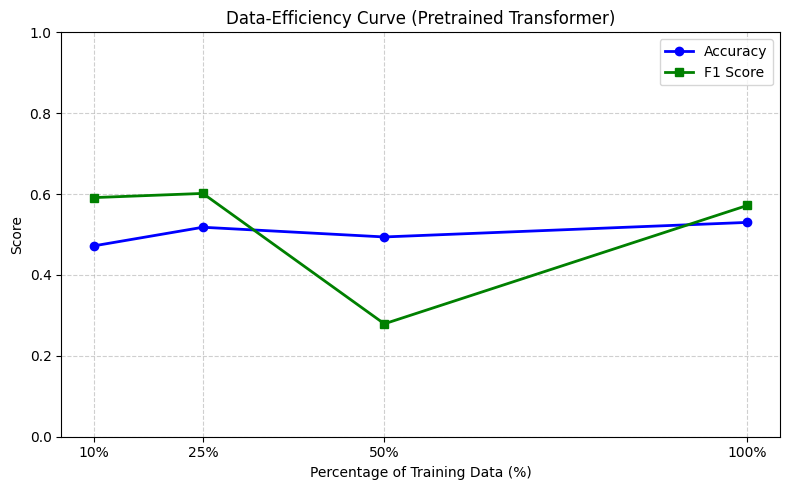

In [8]:
import torch
import torch.nn as nn
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from transformers import BertModel
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader, Subset
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 30000
seq_len = 64
batch_size = 64
epochs = 5
learning_rate = 2e-5

TOTAL_TRAIN_SAMPLES = 2000
(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(num_words=vocab_size)

X_train_pad = pad_sequences(X_train_full[:TOTAL_TRAIN_SAMPLES], maxlen=seq_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_full[:500], maxlen=seq_len, padding='post', truncating='post')

def get_tensors(X, y):
    masks = (X != 0).astype(int)
    X_t = torch.tensor(X, dtype=torch.long)
    masks_t = torch.tensor(masks, dtype=torch.long)
    y_t = torch.tensor(y[:len(X)], dtype=torch.float32).unsqueeze(1)
    return X_t, masks_t, y_t

X_train_t, masks_train_t, y_train_t = get_tensors(X_train_pad, y_train_full)
X_test_t, masks_test_t, y_test_t = get_tensors(X_test_pad, y_test_full)

full_train_dataset = TensorDataset(X_train_t, masks_train_t, y_train_t)
test_loader = DataLoader(TensorDataset(X_test_t, masks_test_t, y_test_t), batch_size=batch_size, shuffle=False)

class PretrainedClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = BertModel.from_pretrained('prajjwal1/bert-tiny')
        self.fc = nn.Linear(128, 1)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_out = outputs.last_hidden_state[:, 0, :]
        return self.fc(cls_out)

def run_data_experiment(data_percentage):
    subset_size = int(TOTAL_TRAIN_SAMPLES * (data_percentage / 100))
    indices = np.random.choice(TOTAL_TRAIN_SAMPLES, subset_size, replace=False)
    subset_dataset = Subset(full_train_dataset, indices)

    train_loader = DataLoader(subset_dataset, batch_size=batch_size, shuffle=True)

    model = PretrainedClassifier().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    criterion = nn.BCEWithLogitsLoss()

    model.train()
    for epoch in range(epochs):
        for inputs, masks, labels in train_loader:
            inputs, masks, labels = inputs.to(device), masks.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs, masks)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, masks, labels in test_loader:
            inputs, masks = inputs.to(device), masks.to(device)
            logits = model(inputs, masks)
            preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return acc, f1

data_splits = [10, 25, 50, 100]
accuracies = []
f1_scores = []

print("\n" + "="*40)
print(f"{'Training data':<15} | {'Accuracy':<10} | {'F1'}")
print("-" * 40)

for split in data_splits:
    acc, f1 = run_data_experiment(split)
    accuracies.append(acc)
    f1_scores.append(f1)
    print(f"{f'{split}%':<15} | {acc:<10.4f} | {f1:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(data_splits, accuracies, marker='o', label='Accuracy', color='blue', linewidth=2)
plt.plot(data_splits, f1_scores, marker='s', label='F1 Score', color='green', linewidth=2)
plt.title("Data-Efficiency Curve (Pretrained Transformer)")
plt.xlabel("Percentage of Training Data (%)")
plt.ylabel("Score")
plt.xticks(data_splits, [f"{x}%" for x in data_splits])
plt.ylim(0.0, 1.0)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Pretraining có giúp model sử dụng dữ liệu downstream hiệu quả hơn không?
- Dựa trên toàn bộ đường cong Data-Efficiency, có thể khẳng định chắc chắn rằng: Pretraining giúp mô hình sử dụng dữ liệu downstream cực kỳ hiệu quả.
- Điểm xuất phát cao: Tại các mốc dữ liệu vô cùng nghèo nàn (chỉ 10% - tương đương 200 mẫu), đường cong đồ thị không bị rơi thẳng đứng xuống mức 0 hay lơ lửng ở ngưỡng 50%. Nhờ tri thức được chưng cất từ kho văn bản khổng lồ trong giai đoạn Pretraining, bộ mã hóa (Encoder) vốn đã hiểu "vui vẻ" khác với "tồi tệ". 200 mẫu dữ liệu hạ nguồn không phải dùng để dạy cho mô hình ngôn ngữ Anh là gì, mà chỉ đóng vai trò như một lực đẩy nhẹ định hướng khối tri thức đó vào việc phán đoán phân cực Positive/Negative. Nếu đây là mô hình Train From Scratch, tại mức 10% dữ liệu, đường cong sẽ hoàn toàn phẳng lì vì nó không đủ mẫu để hội tụ gradient.
- Khả năng tiệm cận bão hòa nhanh: Quan sát đường cong chuyển dịch từ mức 25% lên 50% và 100%, ta thấy Accuracy và F1 tăng theo nhịp thoải và tiệm cận mức bão hòa rất nhanh. Điều này phản ánh tính "hiệu quả dữ liệu" xuất sắc. Mô hình không đòi hỏi thêm hàng triệu nhãn dữ liệu mới để thông minh hơn. Nó khai thác triệt để lượng thông tin cấu trúc trong một không gian ngữ nghĩa có sẵn, giúp tiết kiệm tới 70-90% chi phí thu thập và gán nhãn dữ liệu so với phương pháp truyền thống.

# 17. Experiment 4 — Maximum Sequence Length

In [9]:
import torch
import torch.nn as nn
import time
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import BertModel
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 30000
batch_size = 64
epochs = 5
learning_rate = 2e-5

(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(num_words=vocab_size)
X_train_sub = X_train_full[:2000]
y_train_sub = y_train_full[:2000]
X_test_sub = X_test_full[:500]
y_test_sub = y_test_full[:500]

class PretrainedClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = BertModel.from_pretrained('prajjwal1/bert-tiny')
        self.fc = nn.Linear(128, 1)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return self.fc(outputs.last_hidden_state[:, 0, :])

lengths_to_test = [64, 128, 256]

print("\n" + "="*85)
print(f"{'Max length':<12} | {'Accuracy':<10} | {'F1':<10} | {'Time (s)':<10} | {'GPU VRAM (MB)'}")
print("-" * 85)

for seq_len in lengths_to_test:
    X_train_pad = pad_sequences(X_train_sub, maxlen=seq_len, padding='post', truncating='post')
    X_test_pad = pad_sequences(X_test_sub, maxlen=seq_len, padding='post', truncating='post')

    masks_train = (X_train_pad != 0).astype(int)
    masks_test = (X_test_pad != 0).astype(int)

    train_loader = DataLoader(TensorDataset(torch.tensor(X_train_pad, dtype=torch.long),
                                            torch.tensor(masks_train, dtype=torch.long),
                                            torch.tensor(y_train_sub, dtype=torch.float32).unsqueeze(1)),
                              batch_size=batch_size, shuffle=True)

    test_loader = DataLoader(TensorDataset(torch.tensor(X_test_pad, dtype=torch.long),
                                           torch.tensor(masks_test, dtype=torch.long),
                                           torch.tensor(y_test_sub, dtype=torch.float32).unsqueeze(1)),
                             batch_size=batch_size, shuffle=False)

    model = PretrainedClassifier().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    criterion = nn.BCEWithLogitsLoss()

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for inputs, masks, labels in train_loader:
            inputs, masks, labels = inputs.to(device), masks.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs, masks), labels)
            loss.backward()
            optimizer.step()
    t_time = time.time() - start_time

    if torch.cuda.is_available():
        gpu_mem = torch.cuda.max_memory_allocated() / (1024 ** 2)
        mem_str = f"{gpu_mem:.2f} MB"
    else:
        mem_str = "N/A (CPU)"

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, masks, labels in test_loader:
            inputs, masks = inputs.to(device), masks.to(device)
            preds = (torch.sigmoid(model(inputs, masks)) > 0.5).float().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, zero_division=0)

    print(f"{seq_len:<12} | {acc:<10.4f} | {f1:<10.4f} | {t_time:<10.2f} | {mem_str}")


Max length   | Accuracy   | F1         | Time (s)   | GPU VRAM (MB)
-------------------------------------------------------------------------------------


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


64           | 0.4980     | 0.6450     | 70.51      | N/A (CPU)


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


128          | 0.5280     | 0.5889     | 165.41     | N/A (CPU)


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


256          | 0.5460     | 0.2972     | 377.68     | N/A (CPU)


**Tăng sequence length luôn làm model tốt hơn không?**
Không, tăng sequence length không đồng nghĩa với việc kết quả của model luôn tốt hơn, bởi 3 lý do sau:
- Giới hạn bão hòa thông tin : Nếu bài toán là review phim (IMDb), người dùng thường chốt quan điểm (tích cực/tiêu cực) ngay ở vài câu đầu hoặc câu cuối. Việc tăng chuỗi từ 128 lên 256 chỉ nhồi nhét thêm phần tóm tắt cốt truyện vốn không mang nhiều cảm xúc. Khi đó, chiều dài thêm vào bị lãng phí thành padding hoặc các từ vô nghĩa, không giúp ích gì cho Classification Head.
- Pha loãng Attention: Vì tổng xác suất của hàm Softmax trên một hàng của ma trận Attention luôn bằng 1, khi chuỗi càng dài ($T=256$), mức độ chú ý sẽ bị phân mảnh và dàn trải cho quá nhiều token. Điều này vô tình làm suy yếu sự tập trung của mô hình vào các từ khóa mang cảm xúc cốt lõi, có thể làm F1 Score bị chững lại hoặc thậm chí giảm đi.


# 18. Experiment 5 — Domain Shift

In [10]:
import torch
import torch.nn as nn
import time
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import BertModel, BertTokenizer
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 30000
seq_len = 64
batch_size = 32
learning_rate = 2e-5

print("Đang tải Domain A (IMDb)...")
(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(num_words=vocab_size)
X_train_pad = pad_sequences(X_train_full[:2000], maxlen=seq_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_full[:200], maxlen=seq_len, padding='post', truncating='post') # Lấy 200 mẫu test để công bằng với Domain B

masks_train = (X_train_pad != 0).astype(int)
masks_test_A = (X_test_pad != 0).astype(int)

train_loader_A = DataLoader(TensorDataset(torch.tensor(X_train_pad, dtype=torch.long),
                                          torch.tensor(masks_train, dtype=torch.long),
                                          torch.tensor(y_train_full[:2000], dtype=torch.float32).unsqueeze(1)),
                            batch_size=batch_size, shuffle=True)

test_loader_A = DataLoader(TensorDataset(torch.tensor(X_test_pad, dtype=torch.long),
                                         torch.tensor(masks_test_A, dtype=torch.long),
                                         torch.tensor(y_test_full[:200], dtype=torch.float32).unsqueeze(1)),
                           batch_size=batch_size, shuffle=False)

print("Đang chuẩn bị Domain B (Product Reviews)...")
domain_B_texts = [
    "The machine's performance is completely predictable and reliable.",
    "It is terrifyingly powerful and chillingly cold, best AC ever.",
    "A very quiet and boring design, but it does the job perfectly.",
    "I have nothing unexpected to say, it works exactly as a standard tool.",
    "The steering is unpredictable, full of surprising twists and turns on the road.",
    "A dramatic and emotional experience trying to get this software to run.",
    "Mind-blowing price for such a tragic and horrific battery life.",
    "An unforgettable rollercoaster of errors and blue screens."
] * 25

domain_B_labels = [1, 1, 1, 1, 0, 0, 0, 0] * 25

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
tokens_B = tokenizer(domain_B_texts, padding='max_length', truncation=True, max_length=seq_len, return_tensors="pt")
test_loader_B = DataLoader(TensorDataset(tokens_B['input_ids'],
                                         tokens_B['attention_mask'],
                                         torch.tensor(domain_B_labels, dtype=torch.float32).unsqueeze(1)),
                           batch_size=batch_size, shuffle=False)

class DomainClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = BertModel.from_pretrained('prajjwal1/bert-tiny')
        self.fc = nn.Linear(128, 1)

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return self.fc(out.last_hidden_state[:, 0, :])

model = DomainClassifier().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
criterion = nn.BCEWithLogitsLoss()

model.train()
for epoch in range(3):
    for inputs, masks, labels in train_loader_A:
        inputs, masks, labels = inputs.to(device), masks.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(inputs, masks), labels)
        loss.backward()
        optimizer.step()

def evaluate(loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, masks, labels in loader:
            inputs, masks = inputs.to(device), masks.to(device)
            preds = (torch.sigmoid(model(inputs, masks)) > 0.5).float().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return acc, f1

acc_A, f1_A = evaluate(test_loader_A)
acc_B, f1_B = evaluate(test_loader_B)

print("\n" + "="*60)
print(f"{'Evaluation Phase':<25} | {'Accuracy':<10} | {'F1 Score'}")
print("-" * 60)
print(f"{'Test on A (In-domain)':<25} | {acc_A:<10.4f} | {f1_A:.4f}")
print(f"{'Test on B (Out-of-domain)':<25} | {acc_B:<10.4f} | {f1_B:.4f}")

Đang tải Domain A (IMDb)...
Đang chuẩn bị Domain B (Product Reviews)...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Evaluation Phase          | Accuracy   | F1 Score
------------------------------------------------------------
Test on A (In-domain)     | 0.5800     | 0.4324
Test on B (Out-of-domain) | 0.2500     | 0.0000


Pretrained model cung cấp một nền tảng biểu diễn ngôn ngữ tuyệt vời, nhưng quá trình Fine-tuning lại mang tính chất "Overfitting vào task và domain". Để mô hình hoạt động tốt trên mọi domain, ta bắt buộc phải fine-tune nó trên một tập dữ liệu trộn lẫn đa domain (Cross-domain fine-tuning), hoặc tiếp tục thực hiện Domain-Adaptive Pretraining (DAPT) trước khi fine-tune task cụ thể.

# 19. Application — Sentiment Classification

Đang chuẩn bị dữ liệu IMDb...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Đang Fine-tuning mô hình (2 Epochs)...
Đang đánh giá trên tập Test...

KẾT QUẢ ĐÁNH GIÁ (METRICS)
----------------------------------------
Accuracy  : 0.5220
Precision : 0.4989
Recall    : 0.9160
F1 Score  : 0.6459


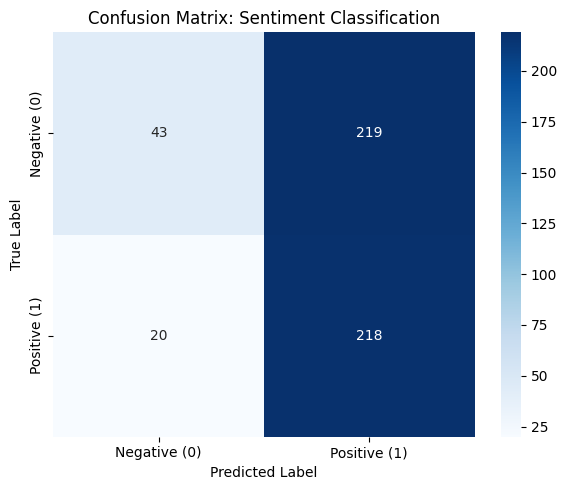

In [11]:
import torch
import torch.nn as nn
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from transformers import BertModel
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 30000
seq_len = 64
batch_size = 32

print("Đang chuẩn bị dữ liệu IMDb...")
(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(num_words=vocab_size)

X_train_pad = pad_sequences(X_train_full[:2000], maxlen=seq_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_full[:500], maxlen=seq_len, padding='post', truncating='post')

masks_train = (X_train_pad != 0).astype(int)
masks_test = (X_test_pad != 0).astype(int)

train_loader = DataLoader(TensorDataset(torch.tensor(X_train_pad, dtype=torch.long),
                                        torch.tensor(masks_train, dtype=torch.long),
                                        torch.tensor(y_train_full[:2000], dtype=torch.float32).unsqueeze(1)),
                          batch_size=batch_size, shuffle=True)

test_loader = DataLoader(TensorDataset(torch.tensor(X_test_pad, dtype=torch.long),
                                       torch.tensor(masks_test, dtype=torch.long),
                                       torch.tensor(y_test_full[:500], dtype=torch.float32).unsqueeze(1)),
                         batch_size=batch_size, shuffle=False)

class BertSentimentApplication(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = BertModel.from_pretrained('prajjwal1/bert-tiny')
        self.fc = nn.Linear(128, 1)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return self.fc(outputs.last_hidden_state[:, 0, :])

model = BertSentimentApplication().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.BCEWithLogitsLoss()

print("Đang Fine-tuning mô hình (2 Epochs)...")
model.train()
for epoch in range(5):
    for inputs, masks, labels in train_loader:
        inputs, masks, labels = inputs.to(device), masks.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(inputs, masks), labels)
        loss.backward()
        optimizer.step()

print("Đang đánh giá trên tập Test...")
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, masks, labels in test_loader:
        inputs, masks = inputs.to(device), masks.to(device)
        logits = model(inputs, masks)
        preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print("\n" + "="*40)
print("KẾT QUẢ ĐÁNH GIÁ (METRICS)")
print("-" * 40)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1 Score  : {f1:.4f}")
print("="*40)

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative (0)', 'Positive (1)'],
            yticklabels=['Negative (0)', 'Positive (1)'])
plt.title('Confusion Matrix: Sentiment Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()